In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q torchxrayvision scikit-image opencv-python-headless matplotlib pillow

Mounted at /content/drive


If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/pspnet_chestxray_best_model_4.pth -O /root/.torchxrayvision/models_data/pspnet_chestxray_best_model_4.pth`
[██████████████████████████████████████████████████]
Testing on image: 1000_IM-0003-1001.dcm.png


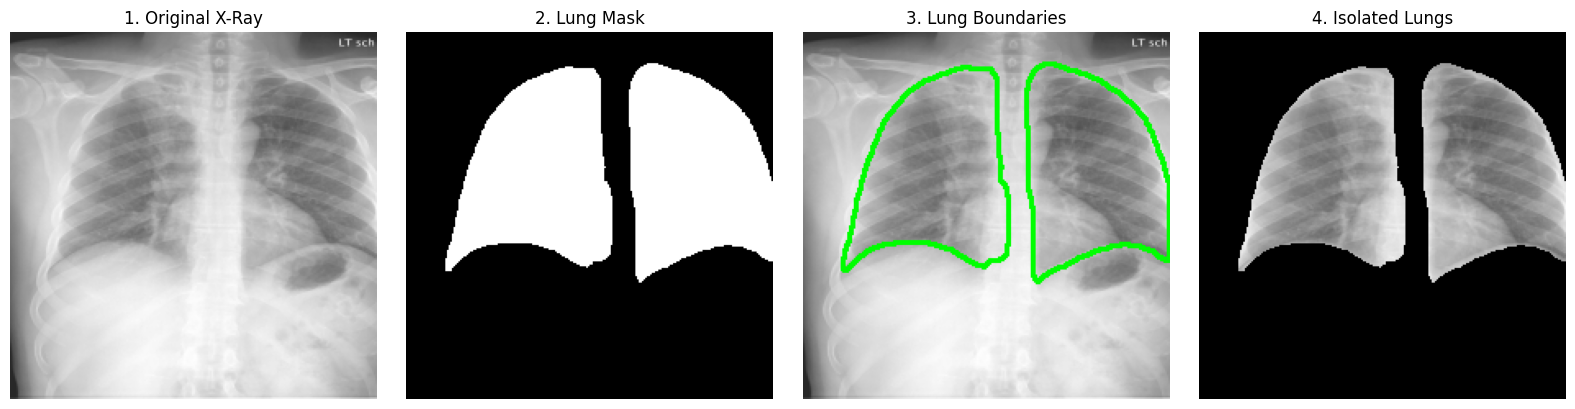

In [2]:
import os
import glob
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
import torchxrayvision as xrv
import torchvision.transforms as transforms
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model = seg_model.to(device).eval()

img_folder = "/content/drive/MyDrive/InnoTech_Dataset/images_224"
image_files = sorted(glob.glob(os.path.join(img_folder, "*.png")))
if not image_files:
    image_files = sorted(glob.glob(os.path.join(img_folder, "*.*")))

sample_path = image_files[0]
print("Testing on image:", os.path.basename(sample_path))

raw_pil = Image.open(sample_path).convert("RGB")
gray_img = np.array(raw_pil.convert("L"), dtype=np.float32)

img_norm = xrv.datasets.normalize(gray_img, 255)
img_norm = img_norm[None, ...]
transform = transforms.Compose([xrv.datasets.XRayResizer(512)])
img_resized = transform(img_norm)
img_tensor = torch.from_numpy(img_resized).unsqueeze(0).to(device)

with torch.no_grad():
    pred = seg_model(img_tensor)

left_idx = seg_model.targets.index("Left Lung")
right_idx = seg_model.targets.index("Right Lung")

left_prob = torch.sigmoid(pred[0, left_idx]).cpu().numpy()
right_prob = torch.sigmoid(pred[0, right_idx]).cpu().numpy()
combined_mask_512 = ((left_prob + right_prob) > 0.5).astype(np.uint8) * 255

orig_224 = np.array(raw_pil.resize((224, 224)), dtype=np.uint8)
mask_224 = cv2.resize(combined_mask_512, (224, 224), interpolation=cv2.INTER_NEAREST)

contours, _ = cv2.findContours(mask_224, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contour_img = orig_224.copy()
cv2.drawContours(contour_img, contours, -1, (0, 255, 0), 2)

isolated_lung = cv2.bitwise_and(orig_224, orig_224, mask=mask_224)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(orig_224)
axes[0].set_title("1. Original X-Ray")
axes[0].axis("off")

axes[1].imshow(mask_224, cmap="gray")
axes[1].set_title("2. Lung Mask")
axes[1].axis("off")

axes[2].imshow(contour_img)
axes[2].set_title("3. Lung Boundaries")
axes[2].axis("off")

axes[3].imshow(isolated_lung)
axes[3].set_title("4. Isolated Lungs")
axes[3].axis("off")

plt.tight_layout()
plt.show()

In [3]:
out_dir = "/content/drive/MyDrive/InnoTech_Dataset/segmentation_output"
os.makedirs(out_dir, exist_ok=True)

for idx, img_path in enumerate(image_files[:10]):
    pil_i = Image.open(img_path).convert("RGB")
    g_i = np.array(pil_i.convert("L"), dtype=np.float32)
    norm_i = xrv.datasets.normalize(g_i, 255)[None, ...]
    res_i = transform(norm_i)
    ten_i = torch.from_numpy(res_i).unsqueeze(0).to(device)

    with torch.no_grad():
        p_i = seg_model(ten_i)

    m_512 = ((torch.sigmoid(p_i[0, left_idx]).cpu().numpy() + torch.sigmoid(p_i[0, right_idx]).cpu().numpy()) > 0.5).astype(np.uint8) * 255
    o_224 = np.array(pil_i.resize((224, 224)), dtype=np.uint8)
    m_224 = cv2.resize(m_512, (224, 224), interpolation=cv2.INTER_NEAREST)

    cnts, _ = cv2.findContours(m_224, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    c_img = o_224.copy()
    cv2.drawContours(c_img, cnts, -1, (0, 255, 0), 2)

    base_name = os.path.splitext(os.path.basename(img_path))[0]
    Image.fromarray(c_img).save(os.path.join(out_dir, f"seg_{base_name}.png"))

print("Saved 10 segmented images to:", out_dir)

Saved 10 segmented images to: /content/drive/MyDrive/InnoTech_Dataset/segmentation_output
